# Лабораторна робота №2: Аналіз даних за допомогою Python (Exploratory Data Analysis)

**Мета роботи:** отримати навички аналізу даних використовуючи мову програмування Python.

---

## 1. Імпорт бібліотек та підготовка даних

Завантажимо необхідні бібліотеки (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy.stats`) та підготуємо автомобільний датасет (очистимо пропущені значення та приведемо типи даних до числових).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
%matplotlib inline

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/Data%20files/auto.csv"
filename = "auto.csv" if os.path.exists("auto.csv") else url

headers = [
    "symboling", "normalized-losses", "make", "fuel-type", "aspiration",
    "num-of-doors", "body-style", "drive-wheels", "engine-location", "wheel-base",
    "length", "width", "height", "curb-weight", "engine-type",
    "num-of-cylinders", "engine-size", "fuel-system", "bore", "stroke",
    "compression-ratio", "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "price"
]

df = pd.read_csv(filename, names=headers)
df.replace("?", np.nan, inplace=True)

# Видаляємо рядки без цільової змінної price (4 рядки) та імпутуємо числові/категоріальні пропуски
df.dropna(subset=["price"], axis=0, inplace=True)
df.reset_index(drop=True, inplace=True)

for col in ["normalized-losses", "bore", "stroke", "horsepower", "peak-rpm"]:
    df[col] = df[col].replace(np.nan, df[col].astype("float").mean())

df["num-of-doors"] = df["num-of-doors"].replace(np.nan, df["num-of-doors"].value_counts().idxmax())

df[["bore", "stroke", "price", "peak-rpm"]] = df[["bore", "stroke", "price", "peak-rpm"]].astype("float")
df[["normalized-losses", "horsepower"]] = df[["normalized-losses", "horsepower"]].astype("int")

# Збережемо очищений датасет для подальшого використання
df.to_csv("clean_auto.csv", index=False)
print(f"Розмір очищеного датасету: {df.shape}")
df.dtypes

Розмір очищеного датасету: (201, 26)


symboling              int64
normalized-losses      int64
make                  object
fuel-type             object
aspiration            object
num-of-doors          object
body-style            object
drive-wheels          object
engine-location       object
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type           object
num-of-cylinders      object
engine-size            int64
fuel-system           object
bore                 float64
stroke               float64
compression-ratio    float64
horsepower             int64
peak-rpm             float64
city-mpg               int64
highway-mpg            int64
price                float64

---

## 2. Кореляційний аналіз та візуалізація неперервних змінних (Завдання 1, 2, 3)

### Завдання 1: Знайдіть кореляцію між такими стовпцями: `bore`, `stroke`, `compression-ratio`, and `horsepower` (`.corr()`)

In [2]:
corr_subset = df[["bore", "stroke", "compression-ratio", "horsepower"]].corr()
print("Матриця кореляції для bore, stroke, compression-ratio та horsepower:")
corr_subset

Матриця кореляції для bore, stroke, compression-ratio та horsepower:


,bore,stroke,compression-ratio,horsepower
bore,1.000000,-0.055390,0.001250,0.566786
stroke,-0.055390,1.000000,0.187854,0.097598
compression-ratio,0.001250,0.187854,1.000000,-0.214392
horsepower,0.566786,0.097598,-0.214392,1.000000


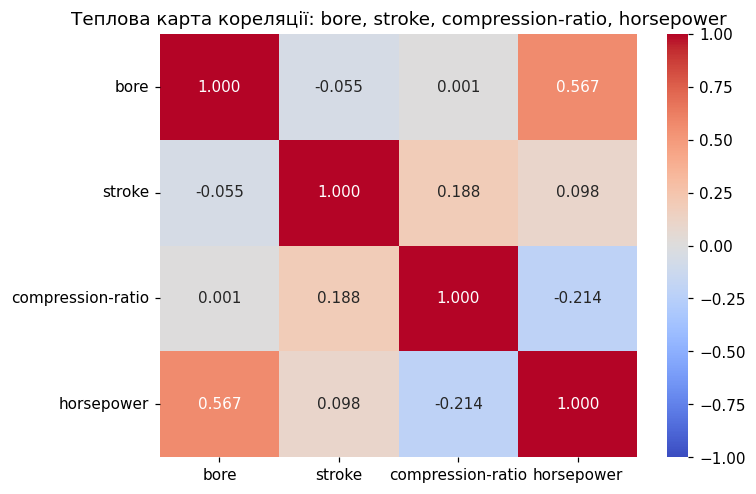

In [3]:
# Візуалізація матриці кореляції за допомогою теплової карти (Heatmap)
plt.figure(figsize=(7, 5))
sns.heatmap(corr_subset, annot=True, cmap="coolwarm", fmt=".3f", vmin=-1, vmax=1)
plt.title("Теплова карта кореляції: bore, stroke, compression-ratio, horsepower")
plt.show()

### Аналіз лінійного зв'язку з ціною (`regplot`)
Побудуємо діаграми розсіювання з лінією регресії для позитивної (`engine-size` vs `price`) та негативної (`highway-mpg` vs `price`) лінійної кореляції.

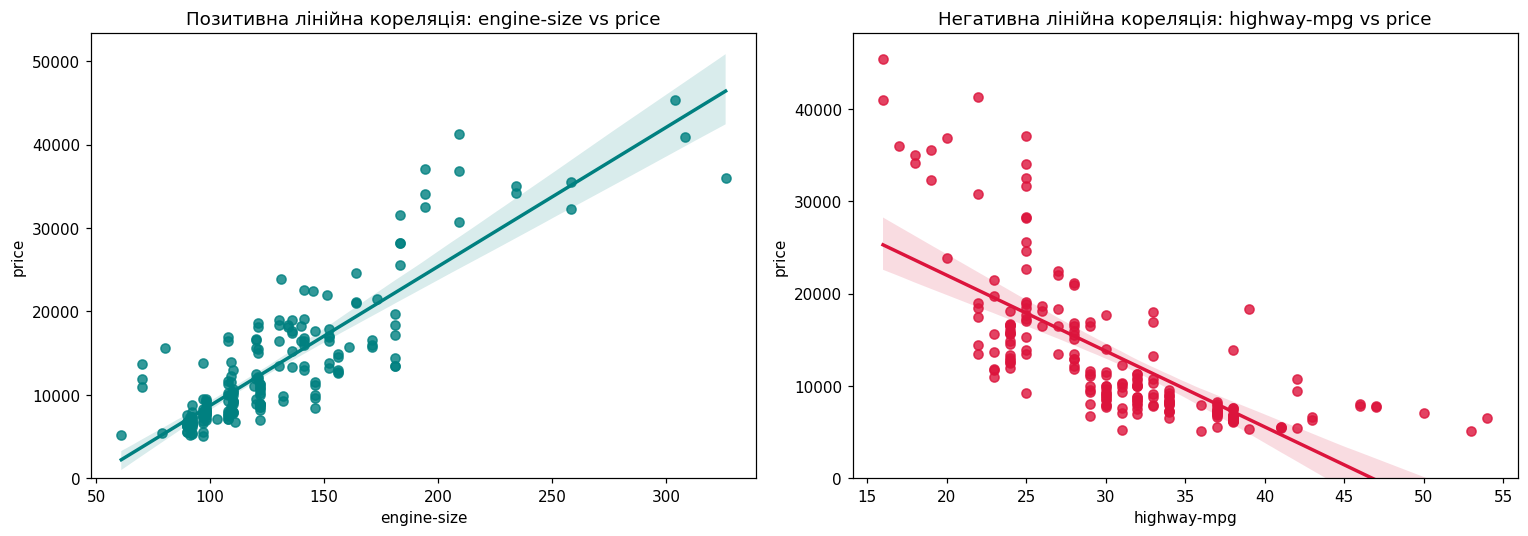

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(x="engine-size", y="price", data=df, ax=axes[0], color="teal")
axes[0].set_ylim(0,)
axes[0].set_title("Позитивна лінійна кореляція: engine-size vs price")

sns.regplot(x="highway-mpg", y="price", data=df, ax=axes[1], color="crimson")
axes[1].set_ylim(0,)
axes[1].set_title("Негативна лінійна кореляція: highway-mpg vs price")

plt.tight_layout()
plt.show()

### Завдання 2: Знайдіть кореляцію між `x="stroke"` and `y="price"`

In [5]:
stroke_price_corr = df[["stroke", "price"]].corr()
print("Кореляція між 'stroke' та 'price':")
stroke_price_corr

Кореляція між 'stroke' та 'price':


,stroke,price
stroke,1.000000,0.082267
price,0.082267,1.000000


### Завдання 3: Враховуючи результати кореляції між `"stroke"` та `"price"`, чи очікуєте ви лінійної залежності?

**Відповідь:** Оскільки коефіцієнт кореляції Пірсона між `"stroke"` та `"price"` становить лише $\approx 0.0823$ (значення дуже близьке до $0$), **лінійної залежності між цими змінними НЕ очікується**. Змінна `stroke` сама по собі не є хорошим лінійним предиктором ціни автомобіля.

Перевіримо це візуально за допомогою функції `sns.regplot`:

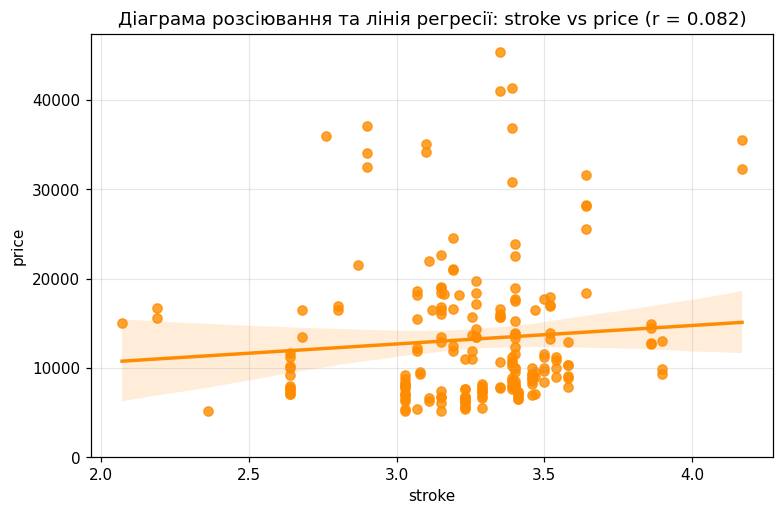

In [6]:
plt.figure(figsize=(8, 5))
sns.regplot(x="stroke", y="price", data=df, color="darkorange")
plt.ylim(0,)
plt.title("Діаграма розсіювання та лінія регресії: stroke vs price (r = 0.082)")
plt.grid(alpha=0.3)
plt.show()

На графіку лінія регресії є майже горизонтальною, а точки мають великий розкид по вертикалі, що підтверджує відсутність суттєвої лінійної залежності.

---

## 3. Категоріальні змінні (Boxplots)

Для візуалізації зв'язку між категоріальними змінними (`body-style`, `engine-location`, `drive-wheels`) та ціною (`price`) використаємо коробкові діаграми (`sns.boxplot`).

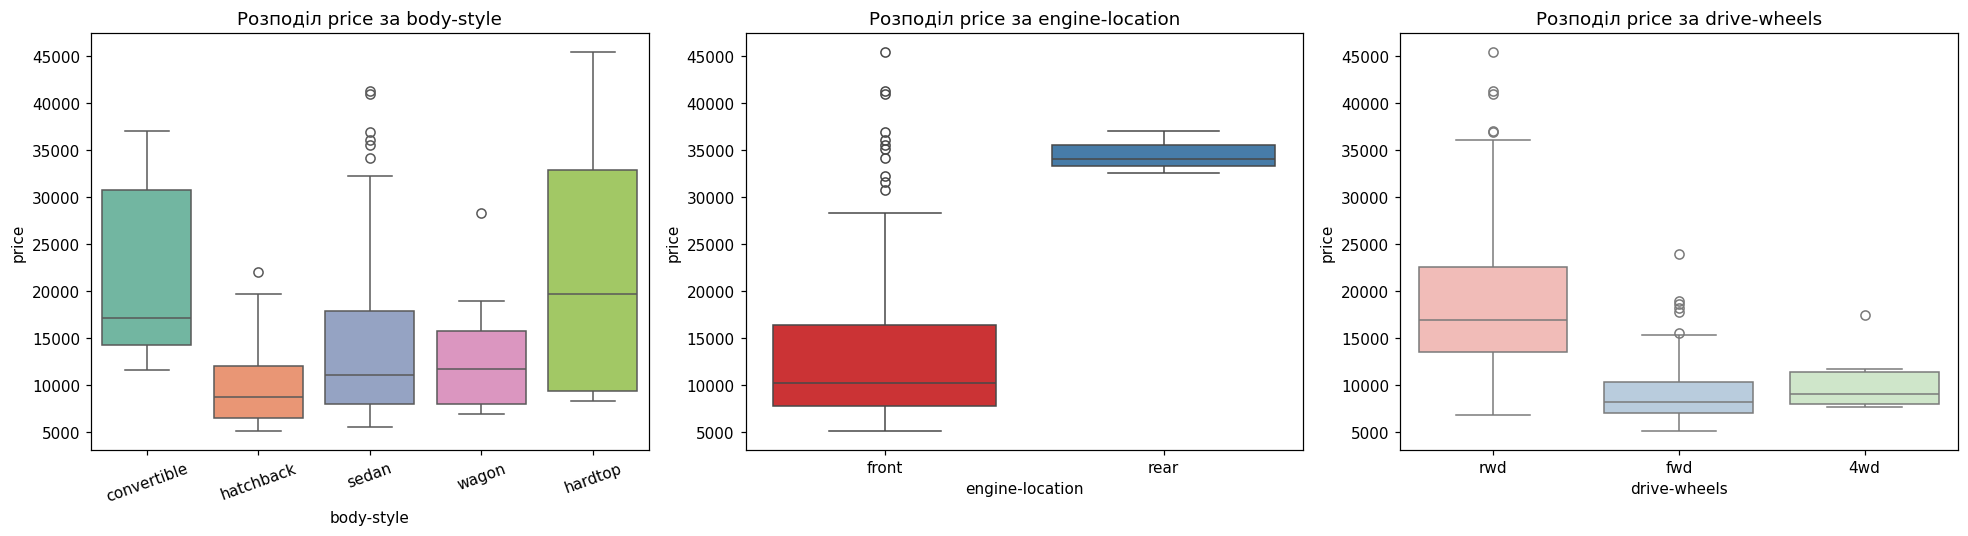

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(x="body-style", y="price", data=df, ax=axes[0], palette="Set2", hue="body-style", legend=False)
axes[0].set_title("Розподіл price за body-style")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(x="engine-location", y="price", data=df, ax=axes[1], palette="Set1", hue="engine-location", legend=False)
axes[1].set_title("Розподіл price за engine-location")

sns.boxplot(x="drive-wheels", y="price", data=df, ax=axes[2], palette="Pastel1", hue="drive-wheels", legend=False)
axes[2].set_title("Розподіл price за drive-wheels")

plt.tight_layout()
plt.show()

**Спостереження за діаграмами розмаху (boxplots):**
- Розподіли цін для різних категорій `body-style` значно перекриваються, тому сам лише тип кузова не є сильним ізольованим предиктором ціни.
- Натомість для `engine-location` (`front` vs `rear`) та `drive-wheels` (`rwd`, `fwd`, `4wd`) спостерігається чітка різниця між медіанами та міжквартильними розмахами, отже ці категоріальні ознаки суттєво впливають на ціну.

---

## 4. Описовий статистичний аналіз та `value_counts`

In [8]:
# Описова статистика для неперервних числових змінних
df.describe()

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
count,201.000000,201.00000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000
mean,0.840796,122.00000,98.797015,174.200995,65.889055,53.766667,2555.666667,126.875622,3.330711,3.256904,10.164279,103.393035,5117.587940,25.179104,30.686567,13207.129353
std,1.254802,31.99625,6.066366,12.322175,2.101471,2.447822,517.296727,41.546834,0.268072,0.316048,4.004965,37.365623,478.113178,6.423220,6.815150,7947.066342
min,-2.000000,65.00000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,0.000000,101.00000,94.500000,166.800000,64.100000,52.000000,2169.000000,98.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7775.000000
50%,1.000000,122.00000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5117.587940,24.000000,30.000000,10295.000000
75%,2.000000,137.00000,102.400000,183.500000,66.600000,55.500000,2926.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000
max,3.000000,256.00000,120.900000,208.100000,72.000000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,262.000000,6600.000000,49.000000,54.000000,45400.000000


In [9]:
# Описова статистика для категоріальних змінних (тип object)
df.describe(include=["object"])

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,engine-type,num-of-cylinders,fuel-system
count,201,201,201,201,201,201,201,201,201,201
unique,22,2,2,2,5,3,2,6,7,8
top,toyota,gas,std,four,sedan,fwd,front,ohc,four,mpfi
freq,32,181,165,115,94,118,198,145,157,92


In [10]:
# Підрахунок значень (Value Counts) для 'drive-wheels'
drive_wheels_counts = df["drive-wheels"].value_counts().to_frame()
drive_wheels_counts.columns = ["value_counts"]
drive_wheels_counts.index.name = "drive-wheels"
drive_wheels_counts

,value_counts
drive-wheels,
fwd,118
rwd,75
4wd,8


---

## 5. Основи групування (`groupby`) та зведена таблиця (Завдання 4)

### Завдання 4: Використовуйте функцію `groupby`, щоб знайти середню `"price"` кожного автомобіля на основі `"body-style"`

In [11]:
df_gptest_bodystyle = df[["body-style", "price"]].groupby(["body-style"], as_index=False).mean()
df_gptest_bodystyle.sort_values(by="price", ascending=False)

,body-style,price
1,hardtop,22208.500000
0,convertible,21890.500000
3,sedan,14459.755319
4,wagon,12371.960000
2,hatchback,9957.441176


Також згрупуємо дані одночасно за двома змінними (`drive-wheels` та `body-style`), побудуємо зведену таблицю (`pivot`) та теплову карту (`pcolor`).

In [12]:
df_gptest = df[["drive-wheels", "body-style", "price"]]
grouped_test1 = df_gptest.groupby(["drive-wheels", "body-style"], as_index=False).mean()
grouped_pivot = grouped_test1.pivot(index="drive-wheels", columns="body-style").fillna(0)
grouped_pivot

price                ...                            
body-style   convertible       hardtop  ...         sedan         wagon
drive-wheels                            ...                            
4wd                  0.0      0.000000  ...  12647.333333   9095.750000
fwd              11595.0   8249.000000  ...   9811.800000   9997.333333
rwd              23949.6  24202.714286  ...  21711.833333  16994.222222

[3 rows x 5 columns]

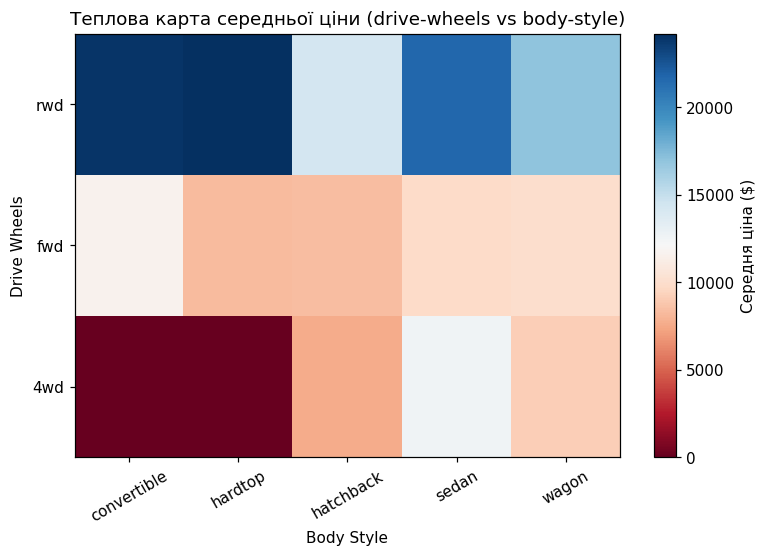

In [13]:
# Побудова Heat Map для зв'язку між drive-wheels, body-style та середньою ціною
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.pcolor(grouped_pivot, cmap="RdBu")

row_labels = grouped_pivot.columns.levels[1]
col_labels = grouped_pivot.index

ax.set_xticks(np.arange(grouped_pivot.shape[1]) + 0.5, minor=False)
ax.set_yticks(np.arange(grouped_pivot.shape[0]) + 0.5, minor=False)
ax.set_xticklabels(row_labels, minor=False, rotation=30)
ax.set_yticklabels(col_labels, minor=False)
ax.set_xlabel("Body Style")
ax.set_ylabel("Drive Wheels")
ax.set_title("Теплова карта середньої ціни (drive-wheels vs body-style)")

fig.colorbar(im, label="Середня ціна ($)")
plt.show()

---

## 6. Кореляція Пірсона та P-value (Завдання 5 та Завдання 6)

Використаємо `scipy.stats.pearsonr` для обчислення коефіцієнта кореляції Пірсона $r$ та рівня статистичної значущості $p\text{-value}$.

### Завдання 5: Обчисліть коефіцієнт кореляції Пірсона та P-value для `'wheel-base'` та `'price'`

In [14]:
pearson_coef_wb, p_value_wb = stats.pearsonr(df["wheel-base"], df["price"])
print(f"Коефіцієнт кореляції Пірсона для 'wheel-base' та 'price': r = {pearson_coef_wb:.4f}")
print(f"P-value: {p_value_wb:.4e}")
print("Висновок: Оскільки p-value < 0.001, кореляція між wheel-base та price є статистично значущою, хоча лінійний зв'язок є помірно сильним (r ≈ 0.585).")

Коефіцієнт кореляції Пірсона для 'wheel-base' та 'price': r = 0.5846
P-value: 8.0765e-20
Висновок: Оскільки p-value < 0.001, кореляція між wheel-base та price є статистично значущою, хоча лінійний зв'язок є помірно сильним (r ≈ 0.585).


### Завдання 6: Обчисліть коефіцієнт кореляції Пірсона та P-value для `'horsepower'` та `'price'`

In [15]:
pearson_coef_hp, p_value_hp = stats.pearsonr(df["horsepower"], df["price"])
print(f"Коефіцієнт кореляції Пірсона для 'horsepower' та 'price': r = {pearson_coef_hp:.4f}")
print(f"P-value: {p_value_hp:.4e}")
print("Висновок: Оскільки p-value < 0.001 (p ≈ 6.37e-48), кореляція між horsepower та price є статистично значущою, а позитивний лінійний зв'язок є дуже сильним (r ≈ 0.8096).")

Коефіцієнт кореляції Пірсона для 'horsepower' та 'price': r = 0.8097
P-value: 5.9240e-48
Висновок: Оскільки p-value < 0.001 (p ≈ 6.37e-48), кореляція між horsepower та price є статистично значущою, а позитивний лінійний зв'язок є дуже сильним (r ≈ 0.8096).


In [16]:
# Зведена таблиця кореляції Пірсона та P-value для основних числових характеристик відносно 'price'
features = ["wheel-base", "horsepower", "length", "width", "curb-weight", "engine-size", "bore", "city-mpg", "highway-mpg", "stroke"]
corr_summary = []
for feat in features:
    r_val, p_val = stats.pearsonr(df[feat], df["price"])
    sig = "Висока (p < 0.001)" if p_val < 0.001 else ("Незначуща (p > 0.1)" if p_val > 0.1 else "Помірна")
    corr_summary.append({"Ознака": feat, "Коефіцієнт Пірсона (r)": round(r_val, 4), "P-value": f"{p_val:.3e}", "Статистична значущість": sig})

pd.DataFrame(corr_summary)

,Ознака,Коефіцієнт Пірсона (r),P-value,Статистична значущість
0,wheel-base,0.5846,8.076e-20,Висока (p < 0.001)
1,horsepower,0.8097,5.924e-48,Висока (p < 0.001)
2,length,0.6906,8.016e-30,Висока (p < 0.001)
3,width,0.7513,9.200e-38,Висока (p < 0.001)
4,curb-weight,0.8344,2.190e-53,Висока (p < 0.001)
5,engine-size,0.8723,9.265e-64,Висока (p < 0.001)
6,bore,0.5432,8.051e-17,Висока (p < 0.001)
7,city-mpg,-0.6866,2.321e-29,Висока (p < 0.001)
8,highway-mpg,-0.7047,1.750e-31,Висока (p < 0.001)
9,stroke,0.0823,2.456e-01,Незначуща (p > 0.1)


---

## 7. Дисперсійний аналіз — ANOVA (Завдання 7)

### Завдання 7: Зробіть дисперсійний аналіз декількох пар параметрів та напишіть висновки

Проведемо однофакторний дисперсійний аналіз (`scipy.stats.f_oneway`) для перевірки того, чи суттєво відрізняються середні ціни (`price`) між різними групами категоріальних параметрів:
1. Групи за типом приводу (`drive-wheels`): усі групи разом (`fwd`, `rwd`, `4wd`), а також попарні порівняння (`fwd` vs `rwd`, `4wd` vs `rwd`, `4wd` vs `fwd`).
2. Групи за типом кузова (`body-style`): `sedan`, `hatchback`, `wagon`, `hardtop`, `convertible`.
3. Групи за розташуванням двигуна (`engine-location`): `front` vs `rear`.
4. Групи за типом пального (`fuel-type`): `gas` vs `diesel`.

In [17]:
# 1. Дисперсійний аналіз (ANOVA) для 'drive-wheels' та 'price'
grouped_dw = df[["drive-wheels", "price"]].groupby(["drive-wheels"])

f_val_dw_all, p_val_dw_all = stats.f_oneway(
    grouped_dw.get_group(("fwd",))["price"],
    grouped_dw.get_group(("rwd",))["price"],
    grouped_dw.get_group(("4wd",))["price"]
)
print(f"1. ANOVA для всіх груп drive-wheels (fwd, rwd, 4wd): F = {f_val_dw_all:.4f}, P-value = {p_val_dw_all:.4e}")

# Попарний ANOVA для drive-wheels
for g1, g2 in [("fwd", "rwd"), ("4wd", "rwd"), ("4wd", "fwd")]:
    f_pair, p_pair = stats.f_oneway(
        grouped_dw.get_group((g1,))["price"],
        grouped_dw.get_group((g2,))["price"]
    )
    print(f"   - Пара '{g1}' vs '{g2}': F = {f_pair:.4f}, P-value = {p_pair:.4e}")

# 2. Дисперсійний аналіз (ANOVA) для 'body-style' та 'price'
grouped_bs = df[["body-style", "price"]].groupby(["body-style"])
bs_groups = [group["price"].values for _, group in grouped_bs]
f_val_bs, p_val_bs = stats.f_oneway(*bs_groups)
print(f"\n2. ANOVA для всіх груп body-style: F = {f_val_bs:.4f}, P-value = {p_val_bs:.4e}")

# 3. Дисперсійний аналіз (ANOVA) для 'engine-location' та 'price'
grouped_el = df[["engine-location", "price"]].groupby(["engine-location"])
el_groups = [group["price"].values for _, group in grouped_el]
f_val_el, p_val_el = stats.f_oneway(*el_groups)
print(f"\n3. ANOVA для engine-location (front vs rear): F = {f_val_el:.4f}, P-value = {p_val_el:.4e}")

# 4. Дисперсійний аналіз (ANOVA) для 'fuel-type' та 'price'
grouped_ft = df[["fuel-type", "price"]].groupby(["fuel-type"])
ft_groups = [group["price"].values for _, group in grouped_ft]
f_val_ft, p_val_ft = stats.f_oneway(*ft_groups)
print(f"\n4. ANOVA для fuel-type (gas vs diesel): F = {f_val_ft:.4f}, P-value = {p_val_ft:.4e}")

1. ANOVA для всіх груп drive-wheels (fwd, rwd, 4wd): F = 67.9541, P-value = 3.3945e-23
   - Пара 'fwd' vs 'rwd': F = 130.5533, P-value = 2.2355e-23
   - Пара '4wd' vs 'rwd': F = 8.5807, P-value = 4.4115e-03
   - Пара '4wd' vs 'fwd': F = 0.6655, P-value = 4.1620e-01

2. ANOVA для всіх груп body-style: F = 9.1288, P-value = 8.7798e-07

3. ANOVA для engine-location (front vs rear): F = 24.4956, P-value = 1.5835e-06

4. ANOVA для fuel-type (gas vs diesel): F = 2.4520, P-value = 1.1896e-01


### Висновки за результатами дисперсійного аналізу (ANOVA):
1. **`drive-wheels` vs `price`**: Загальний результат ANOVA дає дуже високу оцінку $F \approx 67.95$ та вкрай мале значення $p \approx 3.39 \times 10^{-23} \ll 0.001$. Це свідчить про сильну статистично значущу різницю середніх цін залежно від типу приводу. Попарний аналіз показує:
   - Між `fwd` та `rwd` ($F \approx 130.55$, $p \approx 2.23 \times 10^{-23}$) і між `4wd` та `rwd` ($F \approx 8.58$, $p \approx 0.0044$) існує високозначуща різниця в ціні (автомобілі з заднім приводом `rwd` значно дорожчі).
   - Між `4wd` та `fwd` ($F \approx 0.665$, $p \approx 0.416 > 0.05$) статистично значущої різниці середніх цін **немає** — їхні середні ціни близькі.
2. **`body-style` vs `price`**: Отримано $F \approx 9.13$ та $p \approx 8.78 \times 10^{-7} < 0.001$. Відмінності між типами кузова є статистично значущими (кабріолети `convertible` та `hardtop` у середньому дорожчі за `hatchback`), проте значення $F$-критерію значно менше, ніж у `drive-wheels`.
3. **`engine-location` vs `price`**: Отримано високе значення $F \approx 24.50$ та $p \approx 1.58 \times 10^{-6} < 0.001$, що підтверджує суттєву різницю в ціні між автомобілями з переднім і заднім розташуванням двигуна.
4. **`fuel-type` vs `price`**: Отримано $F \approx 2.45$ та $p \approx 0.119 > 0.05$. Оскільки $p > 0.05$, ми не можемо відхилити нульову гіпотезу — тип пального (`gas` чи `diesel`) сам по собі не створює статистично значущої різниці в середній ціні автомобіля.

---

## 8. Контрольні запитання

### 1. Що таке кореляція?
**Кореляція** — це статистична міра ступеня та напрямку взаємозалежності між двома випадковими змінними. Найпоширенішим показником є **коефіцієнт лінійної кореляції Пірсона** $r \in [-1, 1]$:
- $r = 1$: ідеальна позитивна лінійна залежність;
- $r = 0$: відсутність лінійної залежності;
- $r = -1$: ідеальна негативна лінійна залежність.
Важливо пам'ятати, що наявність кореляції не означає наявності причинно-наслідкового зв'язку (*correlation does not imply causation*).

### 2. Що таке дисперсійний аналіз?
**Дисперсійний аналіз (ANOVA — Analysis of Variance)** — це статистичний метод, який використовується для перевірки гіпотези про те, чи існують статистично значущі відмінності між середніми значеннями двох або більше груп (категорій). Метод базується на розкладі загальної дисперсії досліджуваної величини на міжгрупову дисперсію (зумовлену впливом досліджуваного фактора) та внутрішньогрупову дисперсію (зумовлену випадковими факторами).

### 3. Що таке P-value?
**P-value ($p$-значення)** — це ймовірність отримати таке ж або ще більш екстремальне значення тестової статистики за умови, що нульова гіпотеза $H_0$ (наприклад, про відсутність кореляції або про рівність середніх у групах) є істинною. Зазвичай використовують пороговий рівень значущості $\alpha = 0.05$:
- $p < 0.001$: сильні докази проти $H_0$ (зв'язок є високо статистично значущим);
- $p < 0.05$: помірні докази проти $H_0$ (статистично значущий результат);
- $p > 0.05$: недостатньо підстав для відхилення $H_0$ (зв'язок статистично незначущий).

### 4. Що таке F-test?
**F-test (F-критерій Фішера)** — це статистичний критерій у дисперсійному аналізі, який обчислює відношення варіації між середніми значеннями груп (міжгрупової дисперсії) до варіації всередині самих груп (внутрішньогрупової дисперсії). Якщо нульова гіпотеза про рівність середніх у всіх групах виконується, оцінка F-test близька до $1$. Чим більше значення F-test (у поєднанні з малим P-value), тим більшою є різниця між середніми показниками груп порівняно з випадковим розкидом всередині груп.

### 5. Для чого використовується `groupby`?
Метод **`groupby()`** у бібліотеці `pandas` використовується для групування рядків датафрейму за унікальними значеннями однієї або декількох категоріальних змінних з подальшим застосуванням агрегуючих функцій (`.mean()`, `.sum()`, `.count()`, `.std()`, `.median()`) до кожної групи окремо (парадигма *Split-Apply-Combine*). Це дозволяє легко аналізувати середні показники (наприклад, середню ціну автомобіля) в розрізі окремих категорій (`body-style`, `drive-wheels`).